In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score
)

In [ ]:
df = pd.read_csv("diabetes.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
df = df.drop_duplicates().copy()

X = df.drop(columns=["Outcome"])
y = df["Outcome"]


cols = [
    "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI"
]

for col in cols:
    X[col] = X[col].replace(0, np.nan)
    X[col] = X[col].fillna(X[col].median())

print("Missing values after preprocessing:", X.isnull().sum().sum())

Missing values after preprocessing: 0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Normalization completed.")

Normalization completed.


In [7]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

print("KNN model trained successfully.")

KNN model trained successfully.


In [ ]:
cm = confusion_matrix(y_test, y_pred)

accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Confusion Matrix:\n", cm)
print("Accuracy:", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

#cm = confusion_matrix(y_test, y_pred)
#TN, FP, FN, TP = cm.ravel()
#accuracy = (TP + TN) / (TP + TN + FP + FN)
#error_rate = (FP + FN) / (TP + TN + FP + FN)
#precision = TP / (TP + FP) if (TP + FP) != 0 else 0
#recall = TP / (TP + FN) if (TP + FN) != 0 else 0
#f1 = (2 * precision * recall / (precision + recall)
#      if (precision + recall) != 0 else 0)

Confusion Matrix:
 [[83 17]
 [21 33]]
Accuracy: 0.7532
Error Rate: 0.2468
Precision: 0.66
Recall: 0.6111
F1 Score: 0.6346


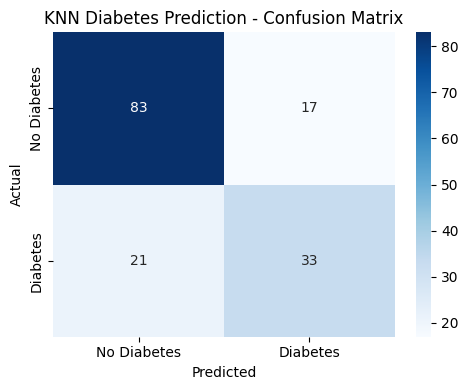

In [9]:
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Diabetes", "Diabetes"],
    yticklabels=["No Diabetes", "Diabetes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Diabetes Prediction - Confusion Matrix")
plt.tight_layout()
plt.savefig("diabetes_confusion_matrix.png", dpi=200)
plt.show()